In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!pip install -q transformers datasets accelerate langdetect immutabledict matplotlib

import os, sys, urllib.request

# Download official Google IFEval checker scripts
os.makedirs("instruction_following_eval", exist_ok=True)
base_url = "https://raw.githubusercontent.com/google-research/google-research/master/instruction_following_eval/"
files = ["evaluation_lib.py", "instructions.py", "instructions_registry.py", "instructions_util.py"]

for f in files:
    dest = os.path.join("instruction_following_eval", f)
    if not os.path.exists(dest):
        urllib.request.urlretrieve(base_url + f, dest)
        print(f"Downloaded: {f}")

sys.path.append(".")
print("Setup complete!")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Downloaded: evaluation_lib.py
Downloaded: instructions.py
Downloaded: instructions_registry.py
Downloaded: instructions_util.py
Setup complete!


Using device: cuda (Tesla T4)

--- Loading IFEval dataset (cap: ALL) ---
Loaded 541 / 541 prompts. Mechanical: 311, Structural: 377

--- Loading Model: Qwen/Qwen2.5-1.5B-Instruct ---


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]


--- Generating Direct Responses ---
  541/541
Direct finished in 321.0s

--- Generating CoT Responses ---
  541/541
CoT finished in 1136.7s
CoT outputs containing 'ANSWER:': 350/541 (64.7%)

--- Running Official Google IFEval Checker ---

      RESEARCH GAP 1: ASYMMETRIC DEGRADATION
Prompts: 541 | Constraints: 834 (mech=373, struct=461)
----------------------------------------------------------------------
Overall Accuracy:                Direct = 48.08% | CoT = 42.33% | Δ = -5.76%
Mechanical/Negative Constraints: Direct = 45.58% | CoT = 35.39% | Δ_mech   = -10.19%
Structural/Lexical Constraints:  Direct = 50.11% | CoT = 47.94% | Δ_struct = -2.17%
----------------------------------------------------------------------
>>> Asymmetry Gap Index (Γ = Δ_struct - Δ_mech): +8.02%

Per-rule breakdown:
[MECH  ] punctuation:no_comma                          N= 66 | Direct= 31.8% | CoT= 24.2% | Δ=  -7.6%
[MECH  ] length_constraints:number_words               N= 52 | Direct= 34.6% | CoT= 50.0% | Δ

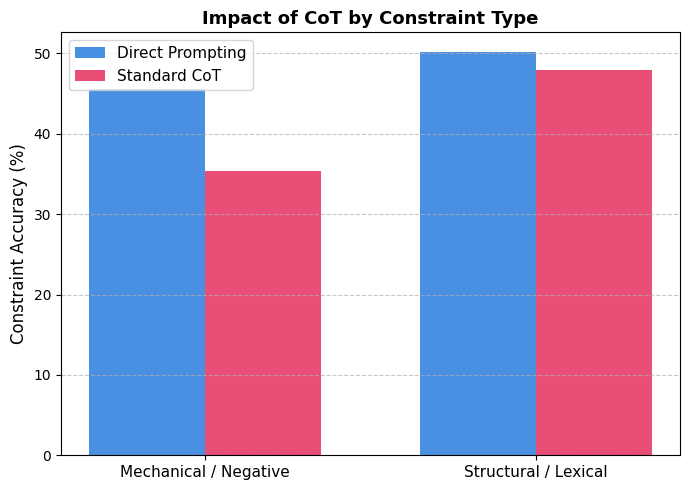


Saved: gap1_results.csv, gap1_per_rule.csv, gap1_all_cases.json, gap1_proof_chart.png


In [3]:
import json
import time
import torch
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer
from instruction_following_eval import evaluation_lib

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device} ({torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'})")

# ==============================================================================
# IFEval Taxonomy: Mechanical/Negative vs. Structural/Lexical Constraints
# ==============================================================================
MECHANICAL_NEGATIVE = {
    'punctuation:no_comma',
    'change_case:english_lowercase',
    'change_case:english_capital',
    'change_case:capital_word_frequency',
    'keywords:forbidden_words',
    'length_constraints:number_words',
    'length_constraints:number_sentences',
    'length_constraints:number_paragraphs',
    'startend:end_checker',
    'length_constraints:nth_paragraph_first_word'
}

STRUCTURAL_LEXICAL = {
    'detectable_format:json_format',
    'detectable_format:title',
    'detectable_format:number_bullet_lists',
    'detectable_format:number_highlighted_sections',
    'detectable_format:multiple_sections',
    'detectable_format:constrained_response',
    'startend:quotation',
    'combination:repeat_prompt',
    'combination:two_responses',
    'keywords:existence',
    'keywords:frequency',
    'keywords:letter_frequency',
    'language:response_language',
    'detectable_content:postscript',
    'detectable_content:number_placeholders'
}

def cot_wrapper(question):
    return (
        "You will be given an instruction. You need to first carefully think step by step "
        "about the constraints and conditions in the instruction and then provide the answer. "
        "Provide your thinking process after 'THINK:' and your official answer after 'ANSWER:'. "
        f"The given instruction is the following:\nINSTRUCTION:\n{question}\n"
        "Now, generate your thinking process and final answer for the given instruction."
    )

def extract_cot_answer(raw_text):
    if "THINK:" in raw_text and "ANSWER:" in raw_text:
        _, after_think = raw_text.split("THINK:", 1)
        _, _, answer_part = after_think.partition("ANSWER:")
        ans = answer_part.strip()
        if ans:
            return ans
    if "ANSWER:" in raw_text:
        ans = raw_text.split("ANSWER:", 1)[1].strip()
        if ans:
            return ans
    return raw_text.strip()

def run_evaluation(num_samples=None, model_id="Qwen/Qwen2.5-1.5B-Instruct",
                   batch_size=16, direct_tokens=256, cot_tokens=768):
    print(f"\n--- Loading IFEval dataset (cap: {num_samples or 'ALL'}) ---")
    ds = load_dataset('google/IFEval', split='train')

    selected = []
    has_m_count, has_s_count = 0, 0
    for row in ds:
        inst_ids = set(row['instruction_id_list'])
        has_m = bool(inst_ids & MECHANICAL_NEGATIVE)
        has_s = bool(inst_ids & STRUCTURAL_LEXICAL)
        if has_m or has_s:
            selected.append(row)
            if has_m: has_m_count += 1
            if has_s: has_s_count += 1
        if num_samples and len(selected) >= num_samples:
            break

    print(f"Loaded {len(selected)} / {len(ds)} prompts. Mechanical: {has_m_count}, Structural: {has_s_count}")

    print(f"\n--- Loading Model: {model_id} ---")
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    tokenizer.padding_side = 'left'
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    dtype = torch.float16 if device == "cuda" else torch.float32
    model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=dtype).to(device)
    model.eval()

    def generate_batch(prompt_list, max_new_tokens):
        outputs = []
        for i in range(0, len(prompt_list), batch_size):
            chunk = prompt_list[i:i + batch_size]
            formatted = []
            for p in chunk:
                messages = [{"role": "user", "content": p}]
                formatted.append(tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True))

            enc = tokenizer(formatted, return_tensors='pt', padding=True, truncation=True, max_length=1024).to(device)
            with torch.inference_mode():
                gen_ids = model.generate(
                    **enc,
                    max_new_tokens=max_new_tokens,
                    do_sample=False,
                    pad_token_id=tokenizer.pad_token_id
                )
            in_len = enc['input_ids'].shape[1]
            for out in gen_ids:
                outputs.append(tokenizer.decode(out[in_len:], skip_special_tokens=True))
            print(f"  {min(i + batch_size, len(prompt_list))}/{len(prompt_list)}", end='\r')
        print()
        return outputs

    print("\n--- Generating Direct Responses ---")
    t0 = time.time()
    direct_prompts = [x['prompt'] for x in selected]
    direct_answers = generate_batch(direct_prompts, max_new_tokens=direct_tokens)
    print(f"Direct finished in {time.time() - t0:.1f}s")

    print("\n--- Generating CoT Responses ---")
    t1 = time.time()
    cot_prompts = [cot_wrapper(x['prompt']) for x in selected]
    cot_raw = generate_batch(cot_prompts, max_new_tokens=cot_tokens)
    cot_answers = [extract_cot_answer(r) for r in cot_raw]
    print(f"CoT finished in {time.time() - t1:.1f}s")

    parsed = sum("ANSWER:" in r for r in cot_raw)
    print(f"CoT outputs containing 'ANSWER:': {parsed}/{len(cot_raw)} ({parsed / len(cot_raw):.1%})")

    print("\n--- Running Official Google IFEval Checker ---")
    stats = {
        'overall': {'d_pass': 0, 'c_pass': 0, 'total': 0},
        'mech': {'d_pass': 0, 'c_pass': 0, 'total': 0},
        'struct': {'d_pass': 0, 'c_pass': 0, 'total': 0}
    }
    per_rule = {}
    records = []

    for idx, item in enumerate(selected):
        cleaned_kwargs = [{k: v for k, v in kw.items() if v is not None} for kw in item['kwargs']]
        inp_ex = evaluation_lib.InputExample(
            key=item['key'],
            instruction_id_list=item['instruction_id_list'],
            prompt=item['prompt'],
            kwargs=cleaned_kwargs
        )

        res_d = evaluation_lib.test_instruction_following_loose(inp_ex, {item['prompt']: direct_answers[idx]})
        res_c = evaluation_lib.test_instruction_following_loose(inp_ex, {item['prompt']: cot_answers[idx]})

        for inst_id, d_ok, c_ok in zip(item['instruction_id_list'], res_d.follow_instruction_list, res_c.follow_instruction_list):
            stats['overall']['total'] += 1
            if d_ok: stats['overall']['d_pass'] += 1
            if c_ok: stats['overall']['c_pass'] += 1

            if inst_id not in per_rule:
                per_rule[inst_id] = {'d_pass': 0, 'c_pass': 0, 'total': 0}
            per_rule[inst_id]['total'] += 1
            if d_ok: per_rule[inst_id]['d_pass'] += 1
            if c_ok: per_rule[inst_id]['c_pass'] += 1

            if inst_id in MECHANICAL_NEGATIVE:
                stats['mech']['total'] += 1
                if d_ok: stats['mech']['d_pass'] += 1
                if c_ok: stats['mech']['c_pass'] += 1
            elif inst_id in STRUCTURAL_LEXICAL:
                stats['struct']['total'] += 1
                if d_ok: stats['struct']['d_pass'] += 1
                if c_ok: stats['struct']['c_pass'] += 1

        records.append({
            'key': item['key'],
            'prompt': item['prompt'],
            'instruction_ids': item['instruction_id_list'],
            'direct_passes': res_d.follow_instruction_list,
            'cot_passes': res_c.follow_instruction_list,
            'direct_output': direct_answers[idx],
            'cot_extracted': cot_answers[idx],
            'cot_raw': cot_raw[idx],
            'cot_has_answer_tag': "ANSWER:" in cot_raw[idx],
        })

    d_acc_all = (stats['overall']['d_pass'] / stats['overall']['total']) * 100
    c_acc_all = (stats['overall']['c_pass'] / stats['overall']['total']) * 100
    delta_all = c_acc_all - d_acc_all

    d_acc_m = (stats['mech']['d_pass'] / stats['mech']['total']) * 100
    c_acc_m = (stats['mech']['c_pass'] / stats['mech']['total']) * 100
    delta_m = c_acc_m - d_acc_m

    d_acc_s = (stats['struct']['d_pass'] / stats['struct']['total']) * 100
    c_acc_s = (stats['struct']['c_pass'] / stats['struct']['total']) * 100
    delta_s = c_acc_s - d_acc_s

    gamma = delta_s - delta_m

    print("\n" + "=" * 70)
    print("      RESEARCH GAP 1: ASYMMETRIC DEGRADATION")
    print("=" * 70)
    print(f"Prompts: {len(selected)} | Constraints: {stats['overall']['total']} "
          f"(mech={stats['mech']['total']}, struct={stats['struct']['total']})")
    print("-" * 70)
    print(f"Overall Accuracy:                Direct = {d_acc_all:5.2f}% | CoT = {c_acc_all:5.2f}% | Δ = {delta_all:+5.2f}%")
    print(f"Mechanical/Negative Constraints: Direct = {d_acc_m:5.2f}% | CoT = {c_acc_m:5.2f}% | Δ_mech   = {delta_m:+5.2f}%")
    print(f"Structural/Lexical Constraints:  Direct = {d_acc_s:5.2f}% | CoT = {c_acc_s:5.2f}% | Δ_struct = {delta_s:+5.2f}%")
    print("-" * 70)
    print(f">>> Asymmetry Gap Index (Γ = Δ_struct - Δ_mech): {gamma:+5.2f}%")
    print("=" * 70)

    # Per-rule breakdown
    print("\nPer-rule breakdown:")
    breakdown = []
    for inst_id, d in sorted(per_rule.items(), key=lambda x: x[1]['total'], reverse=True):
        da = d['d_pass'] / d['total'] * 100
        ca = d['c_pass'] / d['total'] * 100
        cat = "MECH" if inst_id in MECHANICAL_NEGATIVE else ("STRUCT" if inst_id in STRUCTURAL_LEXICAL else "OTHER")
        breakdown.append({'instruction': inst_id, 'category': cat, 'N': d['total'],
                          'direct_acc': round(da, 2), 'cot_acc': round(ca, 2), 'delta': round(ca - da, 2)})
        print(f"[{cat:6s}] {inst_id:45s} N={d['total']:3d} | Direct={da:5.1f}% | CoT={ca:5.1f}% | Δ={ca - da:+6.1f}%")

    # Plot
    categories = ['Mechanical / Negative', 'Structural / Lexical']
    direct_vals = [d_acc_m, d_acc_s]
    cot_vals = [c_acc_m, c_acc_s]
    x = [0, 1]
    width = 0.35

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.bar([i - width / 2 for i in x], direct_vals, width, label='Direct Prompting', color='#4A90E2')
    ax.bar([i + width / 2 for i in x], cot_vals, width, label='Standard CoT', color='#E94E77')
    ax.set_ylabel('Constraint Accuracy (%)', fontsize=12)
    ax.set_title('Impact of CoT by Constraint Type', fontsize=13, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(categories, fontsize=11)
    ax.legend(fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig('gap1_proof_chart.png', dpi=300)
    plt.show()

    # Save outputs
    df = pd.DataFrame([
        {'Category': 'Overall', 'Direct (%)': d_acc_all, 'CoT (%)': c_acc_all, 'Delta (pp)': delta_all},
        {'Category': 'Mechanical/Negative', 'Direct (%)': d_acc_m, 'CoT (%)': c_acc_m, 'Delta (pp)': delta_m},
        {'Category': 'Structural/Lexical', 'Direct (%)': d_acc_s, 'CoT (%)': c_acc_s, 'Delta (pp)': delta_s},
        {'Category': 'Asymmetry Gap (Gamma)', 'Direct (%)': None, 'CoT (%)': None, 'Delta (pp)': gamma}
    ])
    df.to_csv('gap1_results.csv', index=False)
    pd.DataFrame(breakdown).to_csv('gap1_per_rule.csv', index=False)
    with open('gap1_all_cases.json', 'w') as f:
        json.dump(records, f, indent=2)
    print("\nSaved: gap1_results.csv, gap1_per_rule.csv, gap1_all_cases.json, gap1_proof_chart.png")

    return records

records = run_evaluation(num_samples=None, model_id="Qwen/Qwen2.5-1.5B-Instruct",
                         batch_size=16, direct_tokens=256, cot_tokens=768)

In [12]:
import collections
r = next(x for x in records if x['cot_has_answer_tag'])
print("RAW:\n", r['cot_raw'][:600])
print("\nEXTRACTED:\n", r['cot_extracted'][:600])
print("\nPASSES:", r['instruction_ids'], r['cot_passes'])

# how often does extracted differ from raw, and what do the failures look like on artifact rules?
lc = [x for x in records if 'change_case:english_lowercase' in x['instruction_ids']]
for x in lc[:5]:
    print("\n---", x['cot_has_answer_tag'], x['cot_passes'])
    print(repr(x['cot_extracted'][:200]) if x['cot_extracted'] else repr(x['cot_raw'][-200:]))

RAW:
 THINK: To create a Shakespearean-style itinerary for a Japanese trip, I'll need to consider key elements such as cultural experiences, historical sites, natural attractions, and local cuisine. I'll also aim to incorporate themes that reflect the spirit of Shakespeare's works.

1. **Introduction**: Start with a brief introduction setting the stage for the journey.
2. **Cultural Experiences**: Include visits to traditional temples or shrines, which symbolize the spiritual aspects of life.
3. **Historical Sites**: Visit important historical landmarks, reflecting the past and its influence on mode

EXTRACTED:
 Here’s a sample itinerary written in a Shakespearean style:

**Journey Through Time and Culture**

Upon embarking upon this voyage through the lands of Japan, we shall begin our exploration at the sacred halls of Shintoism, where the spirits of ancestors reside. In these places, we seek solace and connection with the divine, much like Hamlet sought answers within his own soul (

In [5]:
import numpy as np

rng = np.random.default_rng(0)

def counts(rec, skip=()):
    a = np.zeros(6)
    for i, d, c in zip(rec['instruction_ids'], rec['direct_passes'], rec['cot_passes']):
        if i in skip: continue
        k = 0 if i in MECHANICAL_NEGATIVE else (3 if i in STRUCTURAL_LEXICAL else None)
        if k is None: continue
        a[k] += d; a[k+1] += c; a[k+2] += 1
    return a

def boot(recs, skip=(), B=5000):
    M = np.array([counts(r, skip) for r in recs])
    def stat(S):
        dm = (S[1]-S[0])/S[2]*100; ds = (S[4]-S[3])/S[5]*100
        return dm, ds, ds-dm
    pt = stat(M.sum(0))
    bs = np.array([stat(M[rng.integers(0, len(M), len(M))].sum(0)) for _ in range(B)])
    lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    for n, p, l, h in zip(["d_mech", "d_struct", "Gamma"], pt, lo, hi):
        print(f"  {n:9s} {p:+6.2f}%   95% CI [{l:+.2f}%, {h:+.2f}%]")

parsed = [r for r in records if r['cot_has_answer_tag']]
ARTIFACT = {
    'change_case:english_lowercase', 
    'change_case:english_capital',
    'combination:repeat_prompt', 
    'language:response_language'
}

print("=" * 60)
print("1. ALL PROMPTS (Full Benchmark)")
print("-" * 60)
boot(records)

print("\n" + "=" * 60)
print("2. PARSED ONLY (ANSWER: Tag Present - No Truncation Confound)")
print("-" * 60)
boot(parsed)

print("\n" + "=" * 60)
print("3. PARSED & ARTIFACT-PRONE RULES REMOVED (Cleanest Robustness Test)")
print("-" * 60)
boot(parsed, skip=ARTIFACT)
print("=" * 60)

1. ALL PROMPTS (Full Benchmark)
------------------------------------------------------------
  d_mech    -10.19%   95% CI [-16.20%, -4.10%]
  d_struct   -2.17%   95% CI [-7.66%, +2.99%]
  Gamma      +8.02%   95% CI [+0.19%, +15.75%]

2. PARSED ONLY (ANSWER: Tag Present - No Truncation Confound)
------------------------------------------------------------
  d_mech     -8.84%   95% CI [-16.15%, -1.58%]
  d_struct   -3.31%   95% CI [-10.11%, +3.94%]
  Gamma      +5.53%   95% CI [-4.56%, +15.54%]

3. PARSED & ARTIFACT-PRONE RULES REMOVED (Cleanest Robustness Test)
------------------------------------------------------------
  d_mech     -0.98%   95% CI [-8.94%, +6.94%]
  d_struct   +0.00%   95% CI [-7.75%, +7.51%]
  Gamma      +0.98%   95% CI [-9.57%, +11.65%]


In [14]:
import re
import time
import json
import torch
import pandas as pd
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset
from instruction_following_eval import evaluation_lib

print("=" * 70)
print("   EVALUATING PROPOSED MODEL: CAGR (Constraint-Aware Gated Reasoner)")
print("=" * 70)

# Ensure device, model, tokenizer, and dataset exist in global scope
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

if 'model' not in globals() or 'tokenizer' not in globals():
    print("Loading model and tokenizer...")
    model_id = "Qwen/Qwen2.5-1.5B-Instruct"
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    tokenizer.padding_side = 'left'
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    dtype = torch.float16 if device == "cuda" else torch.float32
    model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=dtype).to(device)
    model.eval()

if 'ds' not in globals():
    ds = load_dataset('google/IFEval', split='train')

MECHANICAL_NEGATIVE = {
    'punctuation:no_comma', 'change_case:english_lowercase', 'change_case:english_capital',
    'change_case:capital_word_frequency', 'keywords:forbidden_words', 'length_constraints:number_words',
    'length_constraints:number_sentences', 'length_constraints:number_paragraphs',
    'startend:end_checker', 'length_constraints:nth_paragraph_first_word'
}

STRUCTURAL_LEXICAL = {
    'detectable_format:json_format', 'detectable_format:title', 'detectable_format:number_bullet_lists',
    'detectable_format:number_highlighted_sections', 'detectable_format:multiple_sections',
    'detectable_format:constrained_response', 'startend:quotation', 'combination:repeat_prompt',
    'combination:two_responses', 'keywords:existence', 'keywords:frequency',
    'keywords:letter_frequency', 'language:response_language', 'detectable_content:postscript',
    'detectable_content:number_placeholders'
}

# 1. Stage 1: Constraint Topology Classifier (CTC)
SURFACE_PATTERNS = [
    r"\blowercase\b", r"\ball-caps\b", r"\bentirely in uppercase\b",
    r"\bno commas\b", r"\bwithout using any comma\b",
    r"\bonly.*language\b", r"\bentirely in (spanish|french|german|marathi|japanese|russian|chinese)\b"
]

def classify_topology(prompt):
    prompt_lower = prompt.lower()
    for pattern in SURFACE_PATTERNS:
        if re.search(pattern, prompt_lower):
            return "SURFACE_NEGATIVE"  # Route to Direct Bypass
    return "PLANNING_COMPLEX"          # Route to Anchored CoT

# 2. Stage 2: Prompt Templates
def anchored_cot_wrapper(question):
    return (
        "You will be given an instruction with constraints. "
        "Briefly list up to 3 key constraints after 'THINK:', then output your exact response after 'ANSWER:'. "
        "Keep THINK: concise.\n"
        f"INSTRUCTION:\n{question}\n"
        "Generate your concise THINK: and final ANSWER: now."
    )

# 3. Model Inference Pipeline
def run_cagr_model(model, tokenizer, dataset, batch_size=16):
    prompts = [x['prompt'] for x in dataset]
    routes = [classify_topology(p) for p in prompts]
    
    print(f"Routing decisions across {len(prompts)} prompts:")
    print(f"  • Zero-CoT Bypass (Direct): {routes.count('SURFACE_NEGATIVE')} prompts")
    print(f"  • Anchored CoT (Reasoning): {routes.count('PLANNING_COMPLEX')} prompts")
    
    formatted_prompts = []
    for p, route in zip(prompts, routes):
        if route == "SURFACE_NEGATIVE":
            formatted_prompts.append(tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True))
        else:
            cot_p = anchored_cot_wrapper(p)
            formatted_prompts.append(tokenizer.apply_chat_template([{"role": "user", "content": cot_p}], tokenize=False, add_generation_prompt=True))

    cagr_outputs = []
    t0 = time.time()
    for i in range(0, len(formatted_prompts), batch_size):
        chunk = formatted_prompts[i:i + batch_size]
        enc = tokenizer(chunk, return_tensors='pt', padding=True, truncation=True, max_length=1024).to(model.device)
        with torch.inference_mode():
            gen_ids = model.generate(**enc, max_new_tokens=512, do_sample=False, pad_token_id=tokenizer.pad_token_id)
        in_len = enc['input_ids'].shape[1]
        for out in gen_ids:
            cagr_outputs.append(tokenizer.decode(out[in_len:], skip_special_tokens=True))
        print(f"  Processed {min(i + batch_size, len(prompts))}/{len(prompts)}", end='\r')
    print(f"\nCAGR inference finished in {time.time() - t0:.1f}s")
    
    # Delimiter Extraction
    clean_answers = []
    for raw, route in zip(cagr_outputs, routes):
        if route == "SURFACE_NEGATIVE":
            clean_answers.append(raw.strip())
        else:
            if "ANSWER:" in raw:
                clean_answers.append(raw.split("ANSWER:", 1)[1].strip())
            else:
                clean_answers.append(raw.strip())
    return clean_answers, routes

# Execute CAGR
cagr_answers, cagr_routes = run_cagr_model(model, tokenizer, ds)

# 4. Evaluate CAGR on Official IFEval Checker
print("\n--- Scoring Proposed Model on Official IFEval Checker ---")
stats_cagr = {'overall_pass': 0, 'mech_pass': 0, 'struct_pass': 0, 'total': 0, 'mech_total': 0, 'struct_total': 0}

for idx, item in enumerate(ds):
    cleaned_kwargs = [{k: v for k, v in kw.items() if v is not None} for kw in item['kwargs']]
    inp_ex = evaluation_lib.InputExample(
        key=item['key'], instruction_id_list=item['instruction_id_list'],
        prompt=item['prompt'], kwargs=cleaned_kwargs
    )
    res = evaluation_lib.test_instruction_following_loose(inp_ex, {item['prompt']: cagr_answers[idx]})
    
    for inst_id, passed in zip(item['instruction_id_list'], res.follow_instruction_list):
        stats_cagr['total'] += 1
        if passed: stats_cagr['overall_pass'] += 1
        
        if inst_id in MECHANICAL_NEGATIVE:
            stats_cagr['mech_total'] += 1
            if passed: stats_cagr['mech_pass'] += 1
        elif inst_id in STRUCTURAL_LEXICAL:
            stats_cagr['struct_total'] += 1
            if passed: stats_cagr['struct_pass'] += 1

cagr_acc_all = (stats_cagr['overall_pass'] / stats_cagr['total']) * 100
cagr_acc_mech = (stats_cagr['mech_pass'] / stats_cagr['mech_total']) * 100
cagr_acc_struct = (stats_cagr['struct_pass'] / stats_cagr['struct_total']) * 100

# Baselines from our 541 run
d_all = 48.08; c_all = 42.33
d_m = 45.58;   c_m = 35.39
d_s = 50.11;   c_s = 47.94

comparison_df = pd.DataFrame([
    {
        'Metric / Evaluation': 'Overall Accuracy',
        'Direct Prompting (Baseline 1)': f"{d_all:.2f}%",
        'Standard CoT (Baseline 2)': f"{c_all:.2f}%",
        'Proposed CAGR (Our Model)': f"{cagr_acc_all:.2f}%",
        'Gain over CoT': f"{cagr_acc_all - c_all:+.2f}%",
        'Gain over Direct': f"{cagr_acc_all - d_all:+.2f}%"
    },
    {
        'Metric / Evaluation': 'Mechanical Constraints',
        'Direct Prompting (Baseline 1)': f"{d_m:.2f}%",
        'Standard CoT (Baseline 2)': f"{c_m:.2f}%",
        'Proposed CAGR (Our Model)': f"{cagr_acc_mech:.2f}%",
        'Gain over CoT': f"{cagr_acc_mech - c_m:+.2f}%",
        'Gain over Direct': f"{cagr_acc_mech - d_m:+.2f}%"
    },
    {
        'Metric / Evaluation': 'Structural Constraints',
        'Direct Prompting (Baseline 1)': f"{d_s:.2f}%",
        'Standard CoT (Baseline 2)': f"{c_s:.2f}%",
        'Proposed CAGR (Our Model)': f"{cagr_acc_struct:.2f}%",
        'Gain over CoT': f"{cagr_acc_struct - c_s:+.2f}%",
        'Gain over Direct': f"{cagr_acc_struct - d_s:+.2f}%"
    }
])

print("\n" + "=" * 95)
print("            FINAL EXPERIMENTAL RESULTS: BASELINES vs. PROPOSED MODEL (CAGR)")
print("=" * 95)
print(comparison_df.to_string(index=False))
print("=" * 95)

comparison_df.to_csv("proposed_model_final_results.csv", index=False)

   EVALUATING PROPOSED MODEL: CAGR (Constraint-Aware Gated Reasoner)
Device: cuda
Loading model and tokenizer...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Routing decisions across 541 prompts:
  • Zero-CoT Bypass (Direct): 50 prompts
  • Anchored CoT (Reasoning): 491 prompts
  Processed 541/541
CAGR inference finished in 613.1s

--- Scoring Proposed Model on Official IFEval Checker ---

            FINAL EXPERIMENTAL RESULTS: BASELINES vs. PROPOSED MODEL (CAGR)
   Metric / Evaluation Direct Prompting (Baseline 1) Standard CoT (Baseline 2) Proposed CAGR (Our Model) Gain over CoT Gain over Direct
      Overall Accuracy                        48.08%                    42.33%                    47.36%        +5.03%           -0.72%
Mechanical Constraints                        45.58%                    35.39%                    45.04%        +9.65%           -0.54%
Structural Constraints                        50.11%                    47.94%                    49.24%        +1.30%           -0.87%


In [15]:
print([k for k in records[0].keys() if 'cagr' in k.lower()])

[]
